# DeepEval Results & Report

Run DeepEval metrics and produce a comprehensive evaluation report.

In [1]:
import os
import time
while True:
    if os.path.exists("done.txt"):
        with open("done.txt", "r") as f:
            if f.read().strip() == "done-generation-eval-qwen":
                os.remove("done.txt")
                break

    print(".", end="")
    time.sleep(30)

In [2]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from tqdm.auto import tqdm
from openai import OpenAI

from deepeval.test_case import LLMTestCase
from deepeval.metrics import (
    AnswerRelevancyMetric,
    FaithfulnessMetric,
    ContextualPrecisionMetric,
    ContextualRecallMetric,
    ContextualRelevancyMetric,
    HallucinationMetric
)
from deepeval.models import DeepEvalBaseLLM

# ---- Configuration ----

# We use the better model (Gemma 4) as the single judge model for both evaluations
# to ensure a fair comparison and avoid default GPT-4 payment.
JUDGE_MODEL_NAME = "Gemma-4-31B-IT-NVFP4"
MODEL_NAME = "Qwen2.5-VL-7B-Instruct-NVFP4"


LLM_BASE_URL = "http://localhost:8001/v1"

QA_FILE = "./results/qa_pairs.jsonl"
RETRIEVAL_FILE = "./results/retrieval_results.jsonl"
GENERATION_FILE = f"./results/{MODEL_NAME}/generation_results.jsonl"
OUTPUT_FILE = f"./results/{MODEL_NAME}/deepeval_report.jsonl"
PLOT_FILE = f"./results/{MODEL_NAME}/deepeval_comparison.png"


## 1. Load Data

In [3]:
if not all(os.path.exists(f) for f in [QA_FILE, RETRIEVAL_FILE, GENERATION_FILE]):
    raise FileNotFoundError("Required files missing. Run previous notebooks first.")

# Read QA Pairs
with open(QA_FILE, "r", encoding="utf-8") as f:
    qa_pairs = [json.loads(line) for line in f if line.strip()]

# Read Retrieval Results
with open(RETRIEVAL_FILE, "r", encoding="utf-8") as f:
    retrieval_list = [json.loads(line) for line in f if line.strip()]

# Read Generation Results
with open(GENERATION_FILE, "r", encoding="utf-8") as f:
    generation_list = [json.loads(line) for line in f if line.strip()]

# Rebuild the maps for easy lookup
retrieval_map = {r["question"]: r for r in retrieval_list}
generation_map = {r["question"]: r for r in generation_list}

print(f"Loaded {len(qa_pairs)} QA pairs.")
print(f"Loaded {len(retrieval_list)} retrieval results.")
print(f"Loaded {len(generation_list)} generation results.")


Loaded 100 QA pairs.
Loaded 100 retrieval results.
Loaded 100 generation results.


## 1.5 Custom LLM-as-a-Judge Evaluation

We use Gemma 4 as the consistent judge model to evaluate the generated answers before running DeepEval metrics.

In [4]:
import concurrent.futures
from tqdm.auto import tqdm

def evaluate_answer(question, ground_truth, actual_answer):
    prompt = (
        "You are an expert reading comprehension evaluator.\n"
        "Compare the GENERATED ANSWER against the GROUND-TRUTH ANSWER to the QUESTION.\n"
        "Score the GENERATED ANSWER from 0 to 10 based on accuracy and completeness.\n"
        "Criteria:\n"
        "10 = perfect match\n"
        "7-9 = minor omissions or slight inaccuracies\n"
        "4-6 = partially correct, significant gaps\n"
        "1-3 = mostly wrong but some relevance\n"
        "0 = completely wrong or irrelevant\n\n"
        f"QUESTION: {question}\n"
        f"GROUND-TRUTH ANSWER: {ground_truth}\n"
        f"GENERATED ANSWER: {actual_answer}\n\n"
        "Return your evaluation STRICTLY as a JSON object with keys 'score' (int) and 'reasoning' (string)."
    )
    
    client = OpenAI(base_url=LLM_BASE_URL, api_key="not-needed")
    for attempt in range(3):
        try:
            response = client.chat.completions.create(
                model=JUDGE_MODEL_NAME,
                messages=[{"role": "user", "content": prompt}],
                temperature=0.0,
            )
            content = response.choices[0].message.content.strip()
            if content.startswith("```json"):
                content = content[7:-3].strip()
            elif content.startswith("```"):
                content = content[3:-3].strip()
                
            res = json.loads(content)
            if "score" in res and "reasoning" in res:
                return res["score"], res["reasoning"]
        except Exception as e:
            pass
            
    return 0, "Failed to evaluate."

def run_custom_judge():
    print(f"Running Custom LLM-as-a-Judge using model: {JUDGE_MODEL_NAME}...")
    
    def process_item(item):
        q = item["question"]
        gt = item["ground_truth_answer"]
        for s_name, s_data in item["strategies"].items():
            # Evaluate if score/reasoning are not present or need update
            if "score" not in s_data or "judge_reasoning" not in s_data:
                score, reasoning = evaluate_answer(q, gt, s_data["answer"])
                s_data["score"] = score
                s_data["judge_reasoning"] = reasoning
        return item

    with concurrent.futures.ThreadPoolExecutor(max_workers=4) as executor:
        updated_list = list(tqdm(executor.map(process_item, generation_list), total=len(generation_list), desc="Custom Judge Progress"))
    
    # Save back to GENERATION_FILE
    with open(GENERATION_FILE, "w", encoding="utf-8") as f:
        for item in updated_list:
            f.write(json.dumps(item, ensure_ascii=False) + "\n")
            
    print("Custom LLM-as-a-Judge evaluation completed and saved to generation results.")

run_custom_judge()


Running Custom LLM-as-a-Judge using model: Gemma-4-31B-IT-NVFP4...


Custom Judge Progress:   0%|          | 0/100 [00:00<?, ?it/s]

Custom LLM-as-a-Judge evaluation completed and saved to generation results.


## 2. Custom DeepEval vLLM Model

In [5]:
class vLLMModel(DeepEvalBaseLLM):
    def __init__(self, model_name):
        self.model_name = model_name
        self.client = OpenAI(base_url=LLM_BASE_URL, api_key="not-needed")

    def load_model(self):
        return self.client

    def generate(self, prompt: str) -> str:
        try:
            response = self.client.chat.completions.create(
                model=self.model_name,
                messages=[{"role": "user", "content": prompt}],
                temperature=0.0
            )
            return response.choices[0].message.content
        except Exception as e:
            print(f"vLLM Error: {e}")
            return ""

    async def a_generate(self, prompt: str) -> str:
        return self.generate(prompt)

    def get_model_name(self):
        return self.model_name

deepeval_model = vLLMModel(JUDGE_MODEL_NAME)


## 3. Run DeepEval Metrics

In [6]:
import concurrent.futures
import numpy as np
from tqdm.notebook import tqdm 
import json
import os
import logging

# 1. CLEANUP: Disable indicators so they don't break the progress bar
os.environ["DEEPEVAL_SHOW_INDICATOR"] = "false"
logging.getLogger("deepeval").setLevel(logging.ERROR)

# --- Helper Function ---
def process_query(qa, s, metrics, generation_map, retrieval_map):
    q = qa["question"]
    expected = qa["answer"]
    gen_res = generation_map.get(q)
    ret_res = retrieval_map.get(q)
    if not gen_res or not ret_res: return None
    actual = gen_res["strategies"][s]["answer"]
    if s == "base_knowledge":
        context = []
    else:
        context_details = ret_res["hybrid_rerank"]["retrieved_details"]
        context = [c.get("content", "") for c in context_details]
    test_case = LLMTestCase(input=q, actual_output=actual, expected_output=expected, retrieval_context=context)
    query_details = {"question": q, "metrics": {}}
    for metric in metrics:
        try:
            metric.measure(test_case)
            query_details["metrics"][metric.__class__.__name__] = {"score": metric.score, "passed": metric.is_successful()}
        except Exception:
            query_details["metrics"][metric.__class__.__name__] = {"score": 0, "passed": False}
    return query_details

# --- Configuration ---
MAX_WORKERS = 8
metrics_list = [
    AnswerRelevancyMetric(threshold=0.5, model=deepeval_model, include_reason=False),
    FaithfulnessMetric(threshold=0.5, model=deepeval_model, include_reason=False),
    ContextualPrecisionMetric(threshold=0.5, model=deepeval_model, include_reason=False),
    ContextualRecallMetric(threshold=0.5, model=deepeval_model, include_reason=False),
    ContextualRelevancyMetric(threshold=0.5, model=deepeval_model, include_reason=False),
    HallucinationMetric(threshold=0.5, model=deepeval_model, include_reason=False)
]

strategies = ["base_knowledge", "with_context", "sliding_context"]
with open(OUTPUT_FILE, "w", encoding="utf-8") as f: pass
report_summary = { s: {} for s in strategies }

# --- Loop ---
for s in strategies:
    print(f"\nEvaluating Strategy: {s}")
    strategy_results = []
    with concurrent.futures.ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
        future_to_qa = {executor.submit(process_query, qa, s, metrics_list, generation_map, retrieval_map): qa for qa in qa_pairs}
        # This will now be a clean, non-jumping bar!
        for future in tqdm(concurrent.futures.as_completed(future_to_qa), total=len(qa_pairs), desc=f"Progress ({s})", leave=False):
            res = future.result()
            if res:
                res["strategy"] = s
                with open(OUTPUT_FILE, "a", encoding="utf-8") as f:
                    f.write(json.dumps(res, ensure_ascii=False) + "\n")
                strategy_results.append(res)
    
    # Stats for Visualization
    metric_names = [m.__class__.__name__ for m in metrics_list]
    for m_name in metric_names:
        scores = [r["metrics"][m_name]["score"] for r in strategy_results if m_name in r["metrics"]]
        passes = [1 if r["metrics"][m_name]["passed"] else 0 for r in strategy_results if m_name in r["metrics"]]
        report_summary[s][m_name] = {
            "mean_score": float(np.mean(scores)) if scores else 0.0,
            "pass_rate": float(np.mean(passes)) if passes else 0.0
        }
        



Evaluating Strategy: base_knowledge


Progress (base_knowledge):   0%|          | 0/100 [00:00<?, ?it/s]

Output()

Output()

## 4. Visualization

Loaded 300 records | Strategies: ['base_knowledge', 'with_context', 'sliding_context'] | Metrics: ['AnswerRelevancyMetric', 'ContextualPrecisionMetric', 'ContextualRecallMetric', 'ContextualRelevancyMetric', 'FaithfulnessMetric', 'HallucinationMetric']


/tmp/ipykernel_1555855/2308461180.py:170: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax3.set_xticklabels(ax3.get_xticklabels(), rotation=45, ha="right")


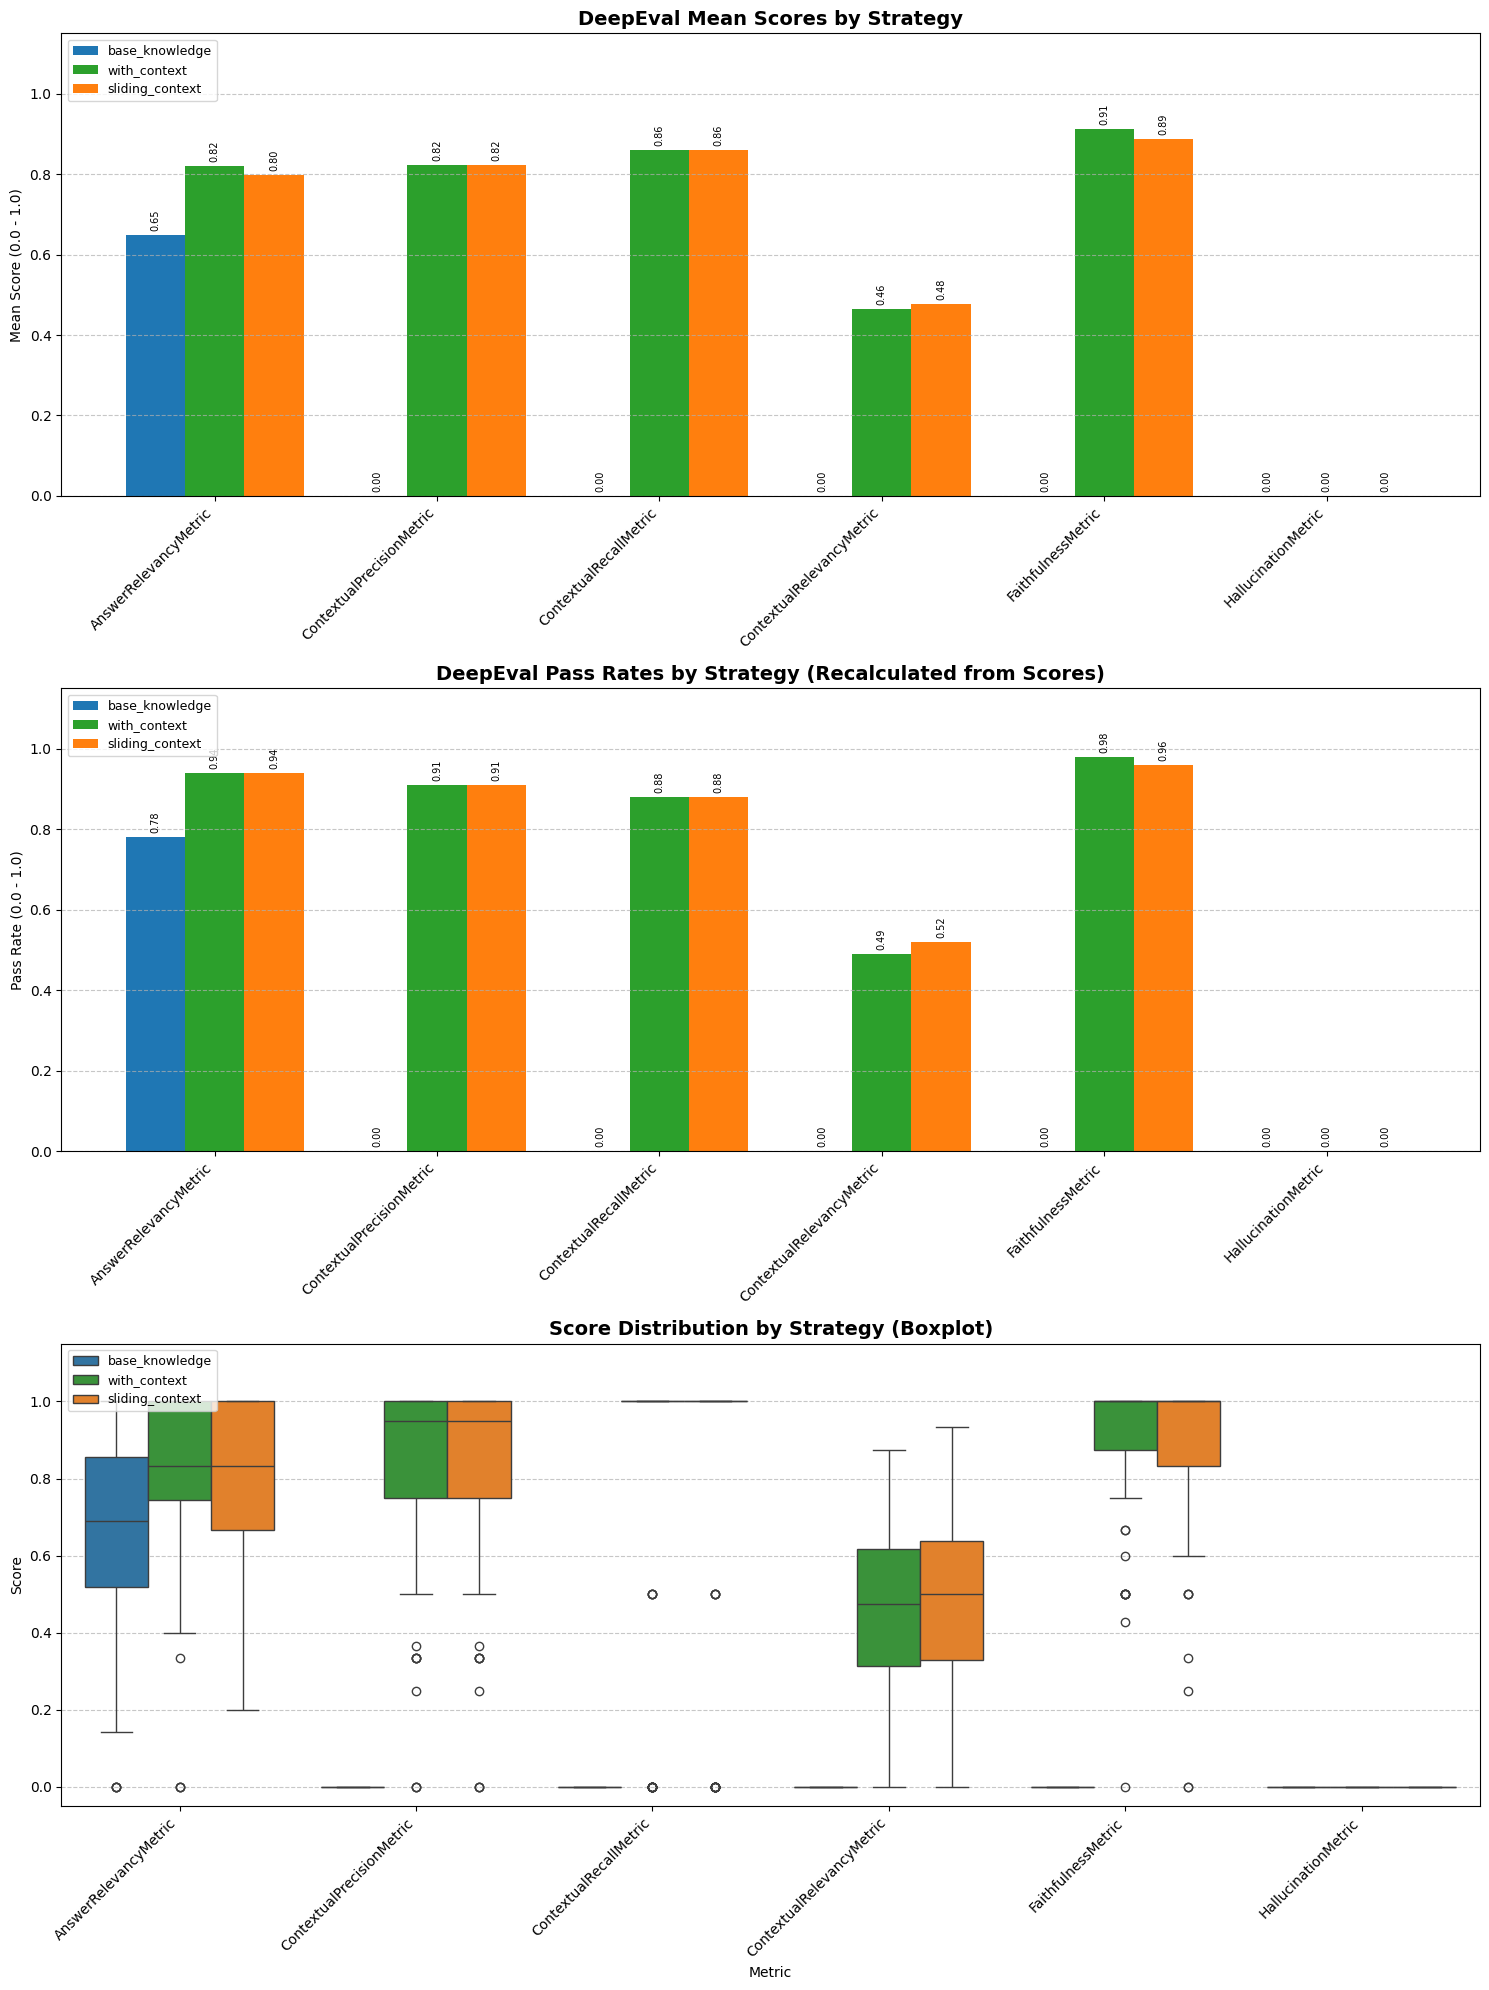

Charts saved to ./results/Qwen2.5-VL-7B-Instruct-NVFP4/combined_charts.png


In [7]:
import json
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# --- Paths ---
JSONL_PATH = f"./results/{MODEL_NAME}/deepeval_report.jsonl"
PLOT_FILE = f"./results/{MODEL_NAME}/combined_charts.png"

os.makedirs(os.path.dirname(PLOT_FILE), exist_ok=True)

# --- Threshold config ---
DEFAULT_THRESHOLD = 0.5

# --- Strategy order & explicit colors ---
desired_order = ["base_knowledge", "with_context","sliding_context"]

strategy_colors = {
    "base_knowledge": "#1f77b4",   # blue
    "sliding_context": "#ff7f0e",  # orange
    "with_context": "#2ca02c",     # green
}

# ====================================================
# 1. LOAD JSONL
# ====================================================
records = []
with open(JSONL_PATH, "r", encoding="utf-8") as f:
    for line_num, line in enumerate(f, 1):
        line = line.strip()
        if not line:
            continue
        try:
            record = json.loads(line)
            if "strategy" not in record or "metrics" not in record:
                print(f"Warning: line {line_num} missing keys, skipping")
                continue
            records.append(record)
        except json.JSONDecodeError as e:
            print(f"Warning: Bad JSON on line {line_num}: {e}")
            continue

if not records:
    raise ValueError(f"No valid records found in {JSONL_PATH}")

# ====================================================
# 2. NUMPY PREPROCESSING — RECALCULATE PASS/FAIL
# ====================================================
first_metrics = records[0].get("metrics", {})
metric_names = sorted(first_metrics.keys())

for r in records:
    metrics = r["metrics"]
    for m in metric_names:
        if m not in metrics or not isinstance(metrics[m], dict):
            continue
        
        score = float(metrics[m].get("score", 0.0))
        passed = score >= DEFAULT_THRESHOLD
        
        metrics[m]["passed"] = passed

# ====================================================
# 3. BUILD SUMMARY WITH NUMPY (for bar charts)
# ====================================================
present_strategies = sorted({r["strategy"] for r in records})
strategies = [s for s in desired_order if s in present_strategies]
if not strategies:
    strategies = present_strategies

report_summary = {}
for s in strategies:
    strat_records = [r for r in records if r["strategy"] == s]
    report_summary[s] = {}
    
    for m in metric_names:
        scores = np.array([
            r["metrics"][m]["score"]
            for r in strat_records
            if m in r["metrics"] and isinstance(r["metrics"][m], dict) and "score" in r["metrics"][m]
        ], dtype=np.float32)
        
        passes = np.array([
            1.0 if r["metrics"][m]["passed"] else 0.0
            for r in strat_records
            if m in r["metrics"] and isinstance(r["metrics"][m], dict) and "passed" in r["metrics"][m]
        ], dtype=np.float32)
        
        report_summary[s][m] = {
            "mean_score": float(np.mean(scores)) if scores.size > 0 else 0.0,
            "pass_rate": float(np.mean(passes)) if passes.size > 0 else 0.0,
        }

print(f"Loaded {len(records)} records | Strategies: {strategies} | Metrics: {metric_names}")

# ====================================================
# 4. BUILD DATAFRAME FOR BOXPLOT
# ====================================================
data = []
for record in records:
    strat = record["strategy"]
    if strat not in strategies:
        continue
    for m_name, m_data in record["metrics"].items():
        if isinstance(m_data, dict) and "score" in m_data:
            data.append({
                "Strategy": strat,
                "Metric": m_name,
                "Score": float(m_data["score"])
            })

df = pd.DataFrame(data)

# ====================================================
# 5. PLOTTING — 3 rows: Mean, Pass Rate, Boxplot
# ====================================================
x = np.arange(len(metric_names))
num_strategies = len(strategies)
width = 0.8 / num_strategies if num_strategies > 0 else 0.2

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 20))

# Build palette in the exact strategy order
palette = [strategy_colors[s] for s in strategies]

# --- Plot 1: Mean Scores ---
for i, s in enumerate(strategies):
    means = [report_summary[s][m]["mean_score"] for m in metric_names]
    rects = ax1.bar(x + i * width, means, width, label=s, color=strategy_colors[s])
    if width >= 0.15:
        ax1.bar_label(rects, padding=3, fmt='%.2f', fontsize=7, rotation=90)

ax1.set_ylabel('Mean Score (0.0 - 1.0)')
ax1.set_title('DeepEval Mean Scores by Strategy', fontsize=14, fontweight='bold')
ax1.set_xticks(x + (num_strategies - 1) * width / 2)
ax1.set_xticklabels(metric_names, rotation=45, ha="right")
ax1.set_ylim(0, 1.15)
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# --- Plot 2: Pass Rates (RECALCULATED) ---
for i, s in enumerate(strategies):
    pass_rates = [report_summary[s][m]["pass_rate"] for m in metric_names]
    rects = ax2.bar(x + i * width, pass_rates, width, label=s, color=strategy_colors[s])
    if width >= 0.15:
        ax2.bar_label(rects, padding=3, fmt='%.2f', fontsize=7, rotation=90)

ax2.set_ylabel('Pass Rate (0.0 - 1.0)')
ax2.set_title('DeepEval Pass Rates by Strategy (Recalculated from Scores)', fontsize=14, fontweight='bold')
ax2.set_xticks(x + (num_strategies - 1) * width / 2)
ax2.set_xticklabels(metric_names, rotation=45, ha="right")
ax2.set_ylim(0, 1.15)
ax2.legend(loc='upper left', fontsize=9)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

# --- Plot 3: Boxplot (distribution) ---
sns.boxplot(
    data=df,
    x="Metric",
    y="Score",
    hue="Strategy",
    order=metric_names,
    hue_order=strategies,
    palette=palette,
    ax=ax3
)
ax3.set_title("Score Distribution by Strategy (Boxplot)", fontsize=14, fontweight='bold')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=45, ha="right")
ax3.legend(loc='upper left', fontsize=9)
ax3.set_ylim(-0.05, 1.15)
ax3.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig(PLOT_FILE, dpi=150, bbox_inches='tight')
plt.show()
print(f"Charts saved to {PLOT_FILE}")

In [9]:
#!/usr/bin/env python3
"""
Fix DeepEval report: Set FaithfulnessMetric to 0 for base_knowledge strategy.
Usage: python fix_faithfulness.py
"""

import json
import sys
from pathlib import Path

# ── CONFIG ──
INPUT_FILE = f"./results/{MODEL_NAME}/deepeval_report.jsonl"
OUTPUT_FILE = f"./results/{MODEL_NAME}/fixed_deepeval_report.jsonl"

# ── MAIN ──
def fix_faithfulness(input_path: str, output_path: str):
    in_path = Path(input_path)
    out_path = Path(output_path)

    if not in_path.exists():
        print(f"Error: File not found: {input_path}")
        sys.exit(1)

    fixed_count = 0
    total_count = 0

    with open(in_path, "r", encoding="utf-8") as fin, \
         open(out_path, "w", encoding="utf-8") as fout:

        for line in fin:
            line = line.strip()
            if not line:
                continue

            total_count += 1
            record = json.loads(line)

            strategy = record.get("strategy", "")
            metrics = record.get("metrics", {})

            if strategy == "base_knowledge" and "FaithfulnessMetric" in metrics:
                old_score = metrics["FaithfulnessMetric"].get("score")
                metrics["FaithfulnessMetric"]["score"] = 0.0
                metrics["FaithfulnessMetric"]["passed"] = False
                fixed_count += 1
                print(f"[{total_count}] Fixed FaithfulnessMetric: {old_score} -> 0.0 (strategy={strategy})")

            fout.write(json.dumps(record, ensure_ascii=False) + "\n")

    # print(f"\nDone. Processed {total_count} records, fixed {fixed_count}.")

if __name__ == "__main__":
    fix_faithfulness(INPUT_FILE, OUTPUT_FILE)

[1] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[2] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[3] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[4] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[5] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[6] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[7] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[8] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[9] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[10] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[11] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[12] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[13] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[14] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[15] Fixed FaithfulnessMetric: 0 -> 0.0 (strategy=base_knowledge)
[16] Fixed Faithful

Loaded 300 records | Strategies: ['base_knowledge', 'with_context', 'sliding_context'] | Metrics: ['AnswerRelevancyMetric', 'ContextualPrecisionMetric', 'ContextualRecallMetric', 'ContextualRelevancyMetric', 'FaithfulnessMetric', 'HallucinationMetric']


/tmp/ipykernel_1555855/1378064329.py:170: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax3.set_xticklabels(ax3.get_xticklabels(), rotation=45, ha="right")


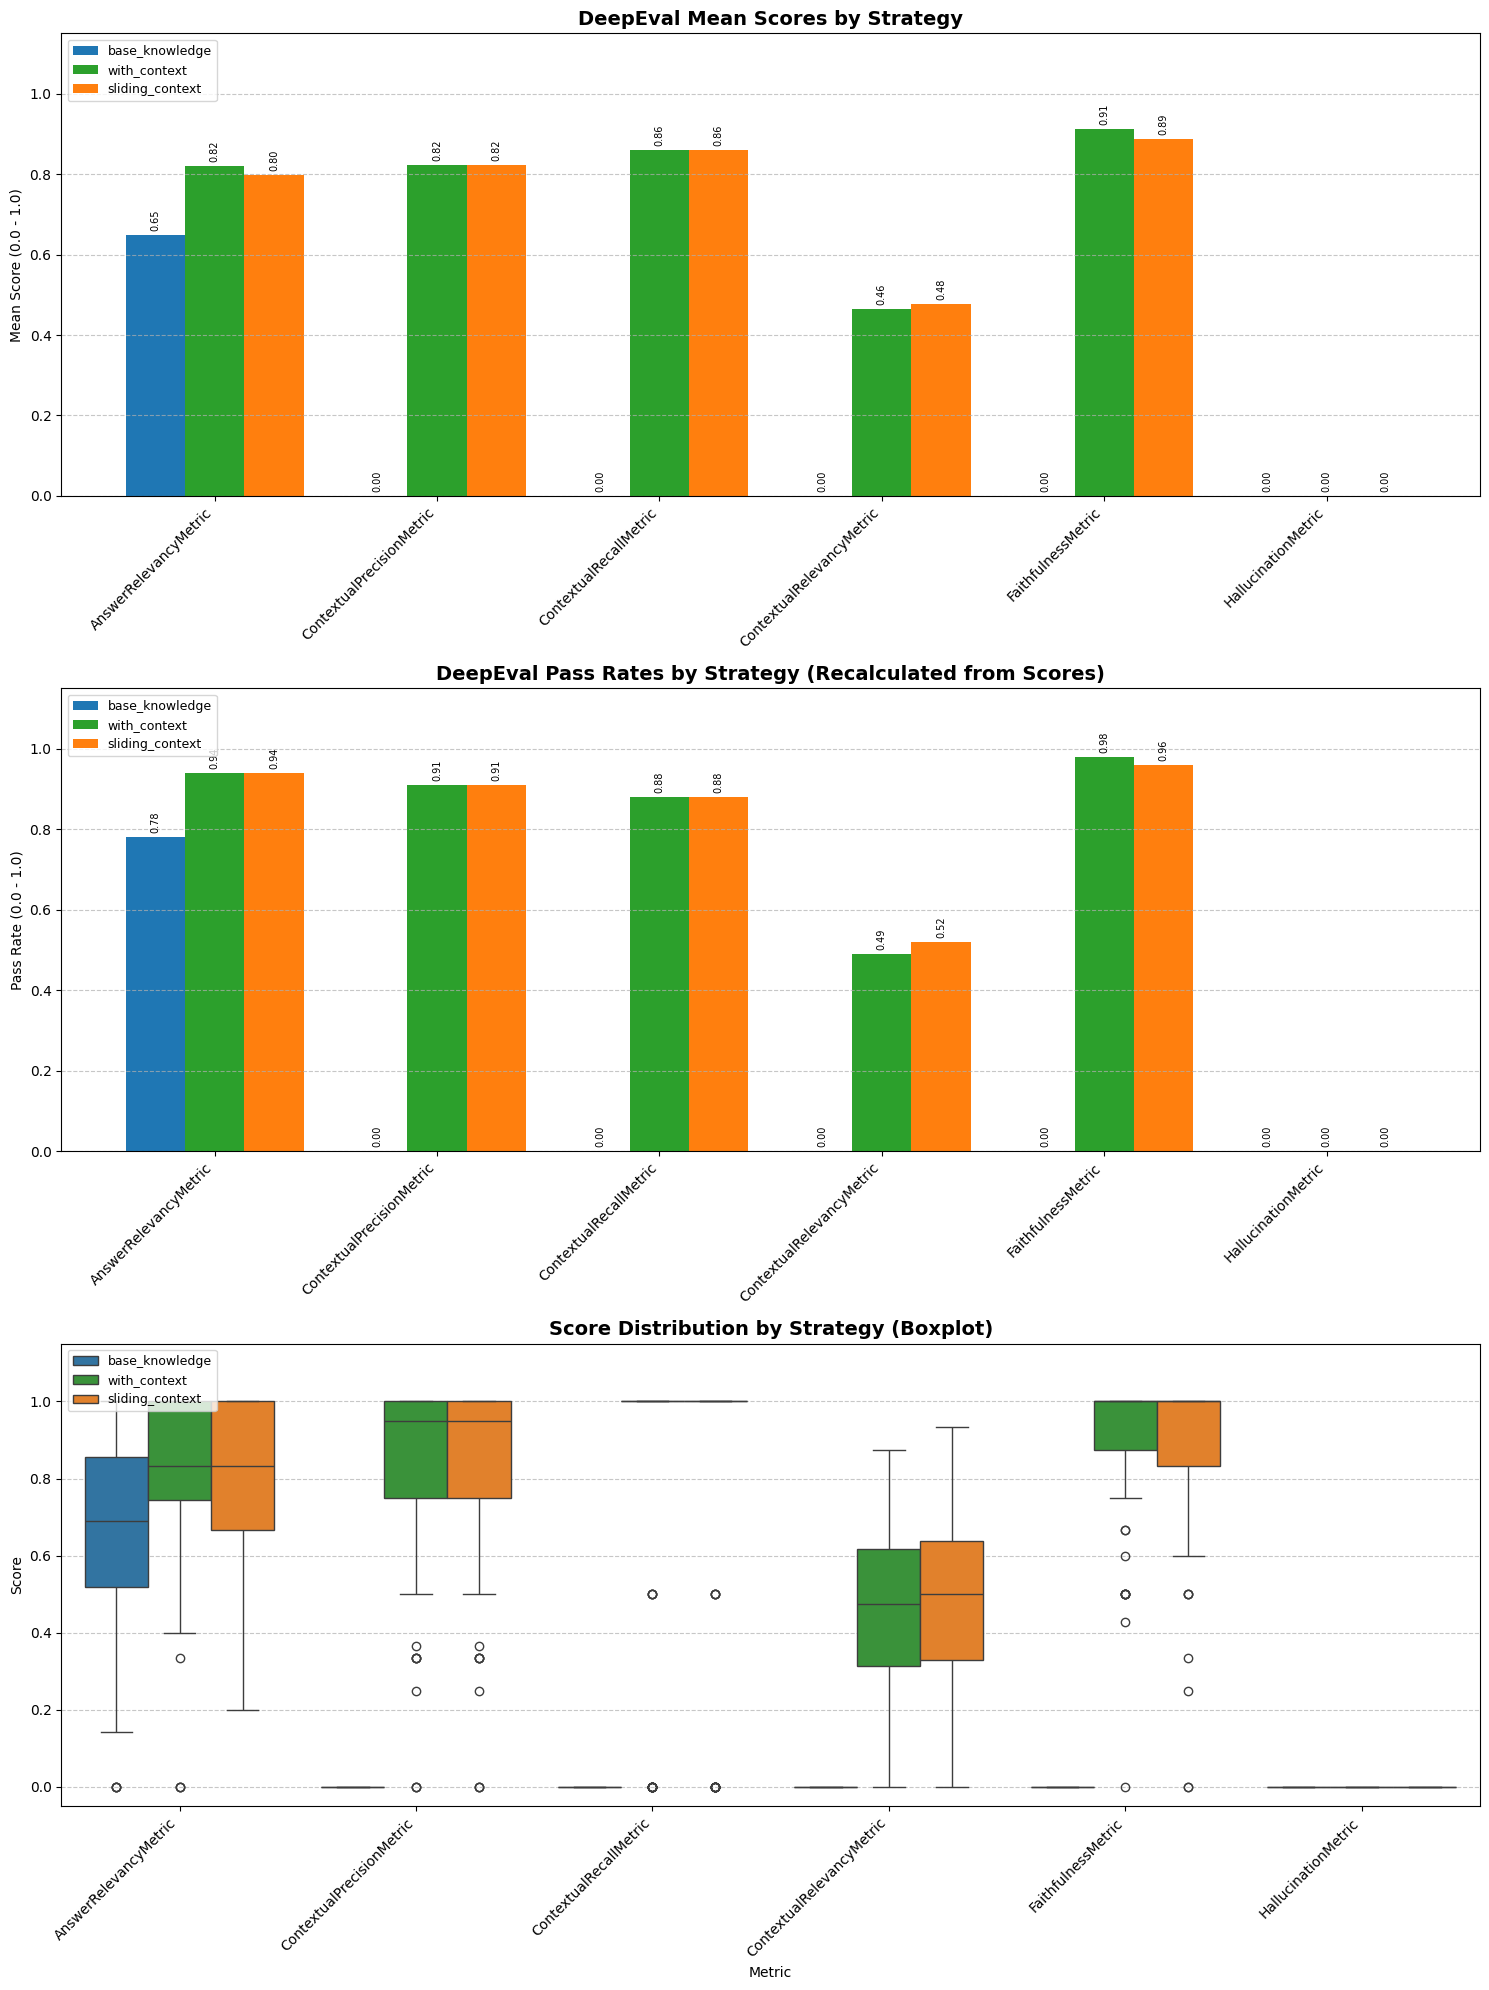

Charts saved to ./results/Qwen2.5-VL-7B-Instruct-NVFP4/combined_charts.png


In [ ]:
import json
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# --- Paths ---
JSONL_PATH = f"./results/{MODEL_NAME}/fixed_deepeval_report.jsonl"
PLOT_FILE = f"./results/{MODEL_NAME}/combined_charts.png"

os.makedirs(os.path.dirname(PLOT_FILE), exist_ok=True)

# --- Threshold config ---
DEFAULT_THRESHOLD = 0.5

# --- Strategy order & explicit colors ---
desired_order = ["base_knowledge", "with_context","sliding_context"]

strategy_colors = {
    "base_knowledge": "#1f77b4",   # blue
    "sliding_context": "#ff7f0e",  # orange
    "with_context": "#2ca02c",     # green
}

# ====================================================
# 1. LOAD JSONL
# ====================================================
records = []
with open(JSONL_PATH, "r", encoding="utf-8") as f:
    for line_num, line in enumerate(f, 1):
        line = line.strip()
        if not line:
            continue
        try:
            record = json.loads(line)
            if "strategy" not in record or "metrics" not in record:
                print(f"Warning: line {line_num} missing keys, skipping")
                continue
            records.append(record)
        except json.JSONDecodeError as e:
            print(f"Warning: Bad JSON on line {line_num}: {e}")
            continue

if not records:
    raise ValueError(f"No valid records found in {JSONL_PATH}")

# ====================================================
# 2. NUMPY PREPROCESSING — RECALCULATE PASS/FAIL
# ====================================================
first_metrics = records[0].get("metrics", {})
metric_names = sorted(first_metrics.keys())

for r in records:
    metrics = r["metrics"]
    for m in metric_names:
        if m not in metrics or not isinstance(metrics[m], dict):
            continue
        
        score = float(metrics[m].get("score", 0.0))
        passed = score >= DEFAULT_THRESHOLD
        
        metrics[m]["passed"] = passed

# ====================================================
# 3. BUILD SUMMARY WITH NUMPY (for bar charts)
# ====================================================
present_strategies = sorted({r["strategy"] for r in records})
strategies = [s for s in desired_order if s in present_strategies]
if not strategies:
    strategies = present_strategies

report_summary = {}
for s in strategies:
    strat_records = [r for r in records if r["strategy"] == s]
    report_summary[s] = {}
    
    for m in metric_names:
        scores = np.array([
            r["metrics"][m]["score"]
            for r in strat_records
            if m in r["metrics"] and isinstance(r["metrics"][m], dict) and "score" in r["metrics"][m]
        ], dtype=np.float32)
        
        passes = np.array([
            1.0 if r["metrics"][m]["passed"] else 0.0
            for r in strat_records
            if m in r["metrics"] and isinstance(r["metrics"][m], dict) and "passed" in r["metrics"][m]
        ], dtype=np.float32)
        
        report_summary[s][m] = {
            "mean_score": float(np.mean(scores)) if scores.size > 0 else 0.0,
            "pass_rate": float(np.mean(passes)) if passes.size > 0 else 0.0,
        }

print(f"Loaded {len(records)} records | Strategies: {strategies} | Metrics: {metric_names}")

# ====================================================
# 4. BUILD DATAFRAME FOR BOXPLOT
# ====================================================
data = []
for record in records:
    strat = record["strategy"]
    if strat not in strategies:
        continue
    for m_name, m_data in record["metrics"].items():
        if isinstance(m_data, dict) and "score" in m_data:
            data.append({
                "Strategy": strat,
                "Metric": m_name,
                "Score": float(m_data["score"])
            })

df = pd.DataFrame(data)

# ====================================================
# 5. PLOTTING — 3 rows: Mean, Pass Rate, Boxplot
# ====================================================
x = np.arange(len(metric_names))
num_strategies = len(strategies)
width = 0.8 / num_strategies if num_strategies > 0 else 0.2

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 20))

# Build palette in the exact strategy order
palette = [strategy_colors[s] for s in strategies]

# --- Plot 1: Mean Scores ---
for i, s in enumerate(strategies):
    means = [report_summary[s][m]["mean_score"] for m in metric_names]
    rects = ax1.bar(x + i * width, means, width, label=s, color=strategy_colors[s])
    if width >= 0.15:
        ax1.bar_label(rects, padding=3, fmt='%.2f', fontsize=7, rotation=90)

ax1.set_ylabel('Mean Score (0.0 - 1.0)')
ax1.set_title('DeepEval Mean Scores by Strategy', fontsize=14, fontweight='bold')
ax1.set_xticks(x + (num_strategies - 1) * width / 2)
ax1.set_xticklabels(metric_names, rotation=45, ha="right")
ax1.set_ylim(0, 1.15)
ax1.legend(loc='upper left', fontsize=9)
ax1.grid(axis='y', linestyle='--', alpha=0.7)

# --- Plot 2: Pass Rates (RECALCULATED) ---
for i, s in enumerate(strategies):
    pass_rates = [report_summary[s][m]["pass_rate"] for m in metric_names]
    rects = ax2.bar(x + i * width, pass_rates, width, label=s, color=strategy_colors[s])
    if width >= 0.15:
        ax2.bar_label(rects, padding=3, fmt='%.2f', fontsize=7, rotation=90)

ax2.set_ylabel('Pass Rate (0.0 - 1.0)')
ax2.set_title('DeepEval Pass Rates by Strategy (Recalculated from Scores)', fontsize=14, fontweight='bold')
ax2.set_xticks(x + (num_strategies - 1) * width / 2)
ax2.set_xticklabels(metric_names, rotation=45, ha="right")
ax2.set_ylim(0, 1.15)
ax2.legend(loc='upper left', fontsize=9)
ax2.grid(axis='y', linestyle='--', alpha=0.7)

# --- Plot 3: Boxplot (distribution) ---
sns.boxplot(
    data=df,
    x="Metric",
    y="Score",
    hue="Strategy",
    order=metric_names,
    hue_order=strategies,
    palette=palette,
    ax=ax3
)
ax3.set_title("Score Distribution by Strategy (Boxplot)", fontsize=14, fontweight='bold')
ax3.set_xticklabels(ax3.get_xticklabels(), rotation=45, ha="right")
ax3.legend(loc='upper left', fontsize=9)
ax3.set_ylim(-0.05, 1.15)
ax3.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig(PLOT_FILE, dpi=150, bbox_inches='tight')
plt.show()
print(f"Charts saved to {PLOT_FILE}")

## 5. Correlation: Retrieval MRR vs Generation Score

In [8]:
mrr_scores = []
gen_scores = []

for qa in qa_pairs:
    q = qa["question"]
    
    ret_res = retrieval_map.get(q)
    gen_res = generation_map.get(q)
    
    if ret_res and gen_res:
        mrr = ret_res["hybrid_rerank"]["metrics"]["mrr"]
        g_score = gen_res["strategies"]["with_context"]["score"]
        
        mrr_scores.append(mrr)
        gen_scores.append(g_score)

if len(mrr_scores) > 1:
    corr, p_value = pearsonr(mrr_scores, gen_scores)
    report_summary["correlation"] = {
        "mrr_vs_generation_score_pearson": float(corr),
        "p_value": float(p_value)
    }
    print(f"\nCorrelation between Retrieval MRR and Generation Score: {corr:.3f} (p-value: {p_value:.3f})")
else:
    print("Not enough data to calculate correlation.")



Correlation between Retrieval MRR and Generation Score: 0.275 (p-value: 0.006)
